# LLM project: predict peptide retention

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/05_LLM_Tools/notebooks/TD4_peptide_RT_solution.ipynb)

Build your own prediction model with help from an LLM. You choose the features,
model and improvements, and explain how you checked the result. You can ask the
assistant to write the code; you remain responsible for the scientific decisions.

The student notebook supplies only data-loading code. This instructor copy includes
one worked implementation and example reasoning to support discussion.

## Instructor guidance

The student copy is an open project brief with one supplied data-loading cell and two
empty workspaces. Do not give students this implementation before they make their choices.
There is no required feature set, algorithm, parameter value or numerical result.

The example below uses amino-acid counts, a mean-only baseline, Ridge and a random forest.
It illustrates one acceptable workflow. Other defensible approaches are welcome.
If students have no LLM access, provide an example response after discussing their plan.
Assess their reasoning and checks, not agreement with this particular model.
The notebook itself is not the course's 40% continuous-assessment component; the quizzes are.

## 1. Meet the data

Peptides are chains of amino acids, written as strings of letters. In reversed-phase
liquid chromatography, their interactions with the column affect when they elute.
More hydrophobic peptides often stay longer, although sequence context and the LC method matter.

We use 6,000 experimentally measured peptides from the DLOmix / ProteomeTools data.
Run the cell below to load the table `data` and preview its first five rows.

| Column | Meaning |
|---|---|
| `sequence` | Peptide amino-acid sequence: the input to your prediction |
| `irt` | Experimentally derived calibrated retention index: the numerical target |

iRT is a reference scale without time units. An iRT of 50 does not mean 50 minutes;
negative values are possible. Larger values correspond to later retention on this scale.
You are building a regression model to predict a number.

In [1]:
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/wilhelm-lab/dlomix/"
    "f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv"
)
data = pd.read_csv(DATA_URL).sample(n=6000, random_state=42).reset_index(drop=True)
data.head()

,sequence,irt
0,DLPVDSLEGEDFEK,91.048184
1,EMCTVEEPNEEFTSR,48.897757
2,AVSVFFR,82.850771
3,ESFIVLESKPK,59.681840
4,TGAVGDLVIIGDR,95.640349


## 2. Decide what to build

Start by asking your LLM to help you plan the analysis, before asking for code.
You choose how to represent sequences as numbers and which model to try.
Ask for a few understandable options and discuss their advantages and limitations.
There is no required algorithm, feature set or set of parameter values.

You could begin with:

> I want to predict the numerical irt target from peptide sequences in a Colab
> table called data. I am an analytical chemist who does not program.
> Suggest a few simple approaches and explain the choices I need to make.
> Keep the project small enough to run on a CPU with freely available tools.
> Help me plan an honest evaluation. Wait for my choices before writing code.

Adapt this prompt to your own questions. You do not need to upload the full dataset:
give the assistant the column descriptions and a few example rows if useful.

Example plan:

Use length and amino-acid counts as a simple sequence representation; this loses residue order.
Compare a training-mean baseline with a scaled Ridge model and then a random forest.
Keep the same 60% / 20% / 20% sequence split for the comparisons and choose using validation MAE.
This example tests a change in model class rather than requiring it to improve performance.

## 3. Build your model with the LLM

Ask for code in small pieces that you can run and discuss. Use the table `data`
already loaded above. You can add code cells when needed; you do not have to
write the Python yourself.

Your analysis should:

- Check missing values and repeated sequences before modelling.
- Keep separate training, validation and test peptides. Identical sequences must
  stay in one group. Use the same split when comparing approaches and record the random seed.
- Turn sequences into features using the representation you chose.
- Fit a simple baseline that ignores sequence, then a model of your choice.
- Learn feature-preparation settings and model parameters from training peptides only.

A baseline could predict the same value for every peptide. Ask the assistant why
that comparison is useful and decide which constant to use.

Check one small example yourself. For instance, if your features count amino acids,
work out a short sequence by hand and compare it with the code's output.
Ask the assistant to explain which code learns from the targets and which data it uses.
If something fails, include the error in a follow-up prompt and check the proposed repair.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

assert data["sequence"].is_unique
assert data["sequence"].str.fullmatch("[ACDEFGHIKLMNPQRSTVWY]+").all()
assert not data.isna().any().any()
assert np.isfinite(data["irt"]).all()
development, test = train_test_split(data, test_size=0.20, random_state=42)
train, validation = train_test_split(development, test_size=0.25, random_state=42)
print("Training:", len(train), "Validation:", len(validation), "Test:", len(test))
assert set(train.sequence).isdisjoint(validation.sequence)
assert set(development.sequence).isdisjoint(test.sequence)

Training: 3600 Validation: 1200 Test: 1200


In [3]:
def make_features(sequences):
    features = pd.DataFrame(index=sequences.index)
    features["length"] = sequences.str.len()
    for amino_acid in "ACDEFGHIKLMNPQRSTVWY":
        features[amino_acid] = sequences.str.count(amino_acid)
    return features

check = make_features(pd.Series(["ACCA"], index=[7]))
assert list(check.columns) == ["length"] + list("ACDEFGHIKLMNPQRSTVWY")
assert check.index.tolist() == [7], "The function must keep the input row index."
assert check.loc[7, "length"] == 4
assert check.loc[7, "A"] == 2 and check.loc[7, "C"] == 2
assert check.loc[7, list("DEFGHIKLMNPQRSTVWY")].eq(0).all()
print("The hand-check passed.")
check

X_train = make_features(train["sequence"])
X_validation = make_features(validation["sequence"])
X_test = make_features(test["sequence"])
y_train = train["irt"]
y_validation = validation["irt"]
y_test = test["irt"]
X_train.head()

The hand-check passed.


,length,A,C,D,E,F,G,H,I,K,...,M,N,P,Q,R,S,T,V,W,Y
5253,10,1,0,0,3,0,0,0,0,0,...,0,0,0,0,1,1,2,1,0,0
547,15,1,0,0,0,1,1,1,0,1,...,0,0,3,1,0,0,0,3,0,0
2801,10,3,2,0,3,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
818,7,0,1,1,1,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,0
4755,17,1,1,2,0,0,0,0,0,0,...,1,3,1,1,1,1,0,1,0,0


The hand-worked `ACCA` example should give length 4, A count 2 and C count 2, with all
other counts zero. This is evidence for a particular feature function; students choosing
another representation should design a check appropriate to their own code.
The pipeline below fits scaling on training features only.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
models = {
    "Linear model": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=2, random_state=42
    ),
}
for model in models.values():
    model.fit(X_train, y_train)

## 4. Compare and improve before opening the test results

Use the validation peptides to compare your model with the baseline.
Choose an error measure and explain it in words. Mean absolute error (MAE) is one
useful option: for a target of 50 and a prediction of 42, the absolute error is 8 iRT units.
MAE averages these distances, so lower is better. It is not classification accuracy.

Try one deliberate change, such as a different representation, model or setting.
Ask the assistant to explain why it might help, then check whether it actually does.
Keep the baseline and previous result for comparison. You can also keep the baseline
as your final choice if the models do not improve on it.

Record your comparison before looking at test results:

| Approach | What changed? | Training error | Validation error |
|---|---|---|---|
| Baseline | | | |
| First model | | | |
| Revised approach | | | |

Write which approach you choose and why. A more complicated model need not be better.

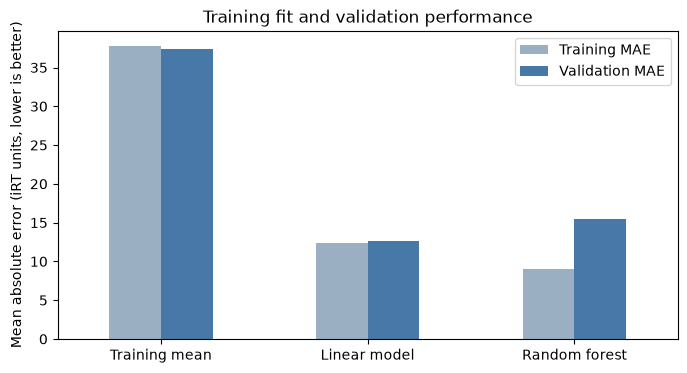

Chosen using validation MAE: Linear model


In [5]:
candidates = {"Training mean": baseline, **models}
scores = pd.DataFrame(index=candidates)
for name, model in candidates.items():
    scores.loc[name, "Training MAE"] = mean_absolute_error(y_train, model.predict(X_train))
    scores.loc[name, "Validation MAE"] = mean_absolute_error(y_validation, model.predict(X_validation))
scores.round(2)

scores.plot.bar(figsize=(8, 4), color=["#9BAFC2", "#4878A8"], rot=0)
plt.ylabel("Mean absolute error (iRT units, lower is better)")
plt.title("Training fit and validation performance")
plt.show()

chosen_name = scores["Validation MAE"].idxmin()
chosen_model = candidates[chosen_name]
print("Chosen using validation MAE:", chosen_name)

Example decision:

The linear model has validation MAE about 12.66 iRT units, versus 37.36 for the mean-only
baseline and 15.48 for the random forest. The forest fits training data better (about 8.96)
than the linear model (12.39), but its validation result is worse. Keep the linear model.
The attempted change did not improve validation performance; that is a useful result.
Students should use their own measured results to justify their choices.

## 5. Assess your final choice

Now ask the LLM for code to evaluate the fixed choice on the test peptides.
Keep these results separate from the validation comparison. Include a plot of predicted
against recorded test iRT and inspect a few of the largest errors.

Check the reported numbers against the table and plot. Does the average error hide some
large mistakes? The error is in iRT units, not minutes.

Do not tune the model in response to the test results and then present the same test
as an independent final check. Further improvements need untouched evaluation data.
Optionally predict iRT for a peptide of your own: without its measured target,
you cannot know how accurate that prediction is.

Selected model: Linear model
Test MAE, iRT units: 12.405966049133562
Mean-only baseline test MAE, iRT units: 39.542253768005835


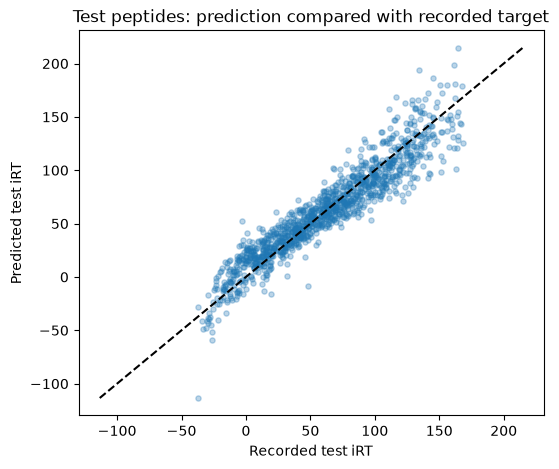

,sequence,irt,Predicted iRT,Absolute error
625,EDLPHHHHHHHQPEAEPR,-37.01,-113.43,76.42
1888,ELAPLQELIEKLTSK,162.99,100.89,62.10
5860,LQVGCAQVVPVPEPPLHPVVPDLPSSVVFPDREAAR,134.40,193.68,59.28
1073,VGDTEGEYHR,48.08,-8.35,56.43
2338,LIEVDDER,-3.25,52.33,55.58


In [6]:
test_predictions = chosen_model.predict(X_test)
test_mae = mean_absolute_error(y_test, test_predictions)
baseline_test_mae = mean_absolute_error(y_test, baseline.predict(X_test))
print("Selected model:", chosen_name)
print("Test MAE, iRT units:", test_mae)
print("Mean-only baseline test MAE, iRT units:", baseline_test_mae)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, test_predictions, alpha=0.3, s=14)
limits = [min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]
plt.plot(limits, limits, color="black", linestyle="--")
plt.xlabel("Recorded test iRT")
plt.ylabel("Predicted test iRT")
plt.title("Test peptides: prediction compared with recorded target")
plt.show()

review = test[["sequence", "irt"]].copy()
review["Predicted iRT"] = test_predictions
review["Absolute error"] = (review["irt"] - review["Predicted iRT"]).abs()
review.nlargest(5, "Absolute error").round(2)

## 6. Explain your work

Answer in your own words, using your results as evidence:

1. What are the samples, input and target? Why is iRT different from minutes?
2. Which features and model did you choose, and why? What information does your representation lose?
3. How did you keep training, validation and test data separate? Show one concrete check
   you made on the code or its output rather than relying on the LLM's explanation.
4. What changed in your revised approach? Use the validation results to justify your final
   choice, then report its test error. Did the results support the LLM's expectations?
5. What can you conclude for this dataset, and what remains untested for another peptide
   population, modification or LC method? Identify one LLM suggestion you corrected or checked.

Example answers for this workflow:

1. Each row is a peptide. Sequence is the input; recorded iRT is the target.
   iRT is dimensionless and needs calibration to become a time for a particular LC method.
2. Counts and length are readable features, and Ridge provides a simple first predictor.
   Counts lose sequence order, so reordered sequences with identical counts receive the same prediction.
3. Each sequence occurs once and the split checks show disjoint groups. Scaling and model
   fitting use training inputs only. The `ACCA` check supplies an independently known answer.
   These checks support specific properties, not proof that every possible error is absent.
4. Switching to a forest reduced training error but increased validation error.
   Validation selected the linear model; its final test MAE is about 12.41 iRT units,
   compared with 39.54 for the fixed mean-only baseline. A more complex model did not help here.
5. This result supports prediction on this sequence split. It does not establish performance
   on another LC method, peptide population or modification. Students must record an actual
   LLM suggestion they checked; do not invent a chat interaction from this worked example.

## 7. Keep your prompts and checks

Save the exact prompts that led to important decisions or corrections. Your code stays in
this notebook; you do not need to paste the entire chat here.

| Exact prompt and assistant used | What you accepted or changed | How you checked it |
|---|---|---|
| | | |

If LLM access is unavailable, ask the instructor for help or an example response and say
what you used. Do not invent a chat interaction. No paid subscription or API key is required
by this notebook.

Your finished notebook should contain your plan, working code, validation comparison,
final test results and plot, answers to the five questions, and a short prompt log.

Instructor note on the log:

The code above is a supplied reference implementation, not a transcript of an actual student
LLM interaction. Students should retain their own prompts and evidence. If an assistant says
that a forest must be better, that MAE bounds every error, or that iRT is measured in minutes,
the student should identify the claim and correct it using their results and the data description.

## Data and reuse

The [DLOmix example CSV](https://raw.githubusercontent.com/wilhelm-lab/dlomix/f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv) contains 34,000 peptide sequences with experimentally
derived iRT targets. We use a fixed random subset of 6,000. The
[ProteomicsML description](https://proteomicsml.org/datasets/retentiontime/DLOmix_RT.html)
connects these data to [ProteomeTools](https://doi.org/10.1038/nmeth.4153), PXD004732.
Credit the experimental authors and the DLOmix contributors. The source is distributed
in the [MIT-licensed DLOmix repository](https://github.com/wilhelm-lab/dlomix/blob/f67623048c8692823cff88c3a7521123697af781/LICENSE).

The two-column file lacks modification annotations, run and batch identifiers, and detailed
LC conditions. Plain sequence strings do not specify every chemical modification.
A sequence-disjoint split can still contain related peptides and does not validate transfer
to another laboratory. Converting iRT to experimental time requires local calibration.
See the [dataset provenance and backup](https://github.com/CompOmics/ML_AI_Analytical_Chemistry_Course/tree/main/datasets/peptide_rt).
This practical is not a reproduction of a published benchmark.